# 02 — Traffic EDA: speed, time, sensors, and location

## Problem
Explore what the updated measurements actually show: speed over time, sensor-to-sensor differences, and how measured PEMS-BAY speeds relate to latitude, longitude, highway, direction, and lane metadata.

## Solution
This notebook uses small, focused cells. PEMS-BAY metadata IDs match all 325 PEMS-BAY traffic columns; METR-LA sensor IDs are a separate network. Coordinates below are therefore used only for PEMS-BAY. Zero speed readings are masked as missing. Every chart is based on observed CSV values, not simulated traffic.

## 1. Imports, files, and matched PEMS-BAY sensors

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
FIG.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)

bay = pd.read_csv(DATA / 'PEMS-BAY.csv', index_col=0, parse_dates=True).astype('float32')
bay.columns = bay.columns.astype(str)
bay = bay.where(bay > 0)
meta = pd.read_csv(DATA / 'PEMS-BAY-META.csv', dtype={'sensor_id': str})
meta['sensor_id'] = meta['sensor_id'].astype(str)
meta = meta.set_index('sensor_id', drop=False).loc[bay.columns].reset_index(drop=True)
assert meta['sensor_id'].tolist() == bay.columns.tolist()
assert meta[['Latitude', 'Longitude']].notna().all().all()

la = pd.read_csv(DATA / 'METR-LA.csv', index_col=0, parse_dates=True).astype('float32').where(lambda x: x > 0)
print(f'PEMS-BAY: {bay.shape[0]:,} timestamps x {bay.shape[1]} sensors; metadata rows: {len(meta)}')
print(f'METR-LA: {la.shape[0]:,} timestamps x {la.shape[1]} sensors')
print('PEMS-BAY coordinate bounds:', meta.Latitude.min(), meta.Latitude.max(), meta.Longitude.min(), meta.Longitude.max())
print('Speed only: flow and occupancy are not included in the supplied traffic CSVs.')

PEMS-BAY: 52,116 timestamps x 325 sensors; metadata rows: 325
METR-LA: 34,272 timestamps x 207 sensors
PEMS-BAY coordinate bounds: 37.250424 37.427486 -122.07953899999998 -121.840267
Speed only: flow and occupancy are not included in the supplied traffic CSVs.


## 2. Inspect metadata and traffic rows

In [2]:
display(meta[['sensor_id', 'Fwy', 'Dir', 'Latitude', 'Longitude', 'Length', 'Lanes', 'Name']].head(10))
display(bay.iloc[:5, :8].round(2))
print('PEMS-BAY speed values are in the supplied dataset units; timestamps are five-minute intervals.')

,sensor_id,Fwy,Dir,Latitude,Longitude,Length,Lanes,Name
0,400001,101,N,37.364085,-121.901149,0.265,5,NB 880 rm-n-loop
1,400017,85,S,37.253303,-121.945440,0.430,4,BASCOM AVE
2,400030,880,S,37.359087,-121.906538,0.250,3,N FIRST ST
3,400040,87,S,37.294949,-121.873109,0.440,3,Curtner Ave rm-s-loop
4,400045,880,N,37.363402,-121.902233,0.350,4,SB 101 rm-n-loop
5,400052,85,N,37.255791,-121.875479,0.555,3,Almaden Expwy
6,400057,880,N,37.335022,-121.935522,0.750,3,Bascom Ave rm-n-diag
7,400059,85,S,37.250481,-121.907735,1.005,3,Camden Ave rm-s-diag
8,400065,87,S,37.320292,-121.890281,0.450,2,NB & SB 280 rm-s-conn
9,400069,101,S,37.385758,-121.977493,0.360,4,Great America Pkwy rm-s-diag


,400001,400017,400030,400040,400045,400052,400057,400059
2017-01-01 00:00:00,71.400002,67.800003,70.500000,67.400002,68.800003,66.599998,66.800003,68.000000
2017-01-01 00:05:00,71.599998,67.500000,70.599998,67.500000,68.699997,66.599998,66.800003,67.800003
2017-01-01 00:10:00,71.599998,67.599998,70.199997,67.400002,68.699997,66.099998,66.800003,67.800003
2017-01-01 00:15:00,71.099998,67.500000,70.300003,68.000000,68.500000,66.699997,66.599998,67.699997
2017-01-01 00:20:00,71.699997,67.800003,70.199997,68.099998,68.400002,66.900002,66.099998,67.699997


PEMS-BAY speed values are in the supplied dataset units; timestamps are five-minute intervals.


## 3. Dataset coverage and missing readings

In [3]:
quality = pd.DataFrame({
    'dataset': ['METR-LA', 'PEMS-BAY'],
    'timestamps': [len(la), len(bay)],
    'sensors': [la.shape[1], bay.shape[1]],
    'missing_speed_percent': [la.isna().to_numpy().mean() * 100, bay.isna().to_numpy().mean() * 100],
    'mean_speed': [la.stack().mean(), bay.stack().mean()],
    'median_speed': [la.stack().median(), bay.stack().median()]
})
display(quality.round(3))
quality.to_csv(METRICS / 'eda_dataset_summary.csv', index=False)

,dataset,timestamps,sensors,missing_speed_percent,mean_speed,median_speed
0,METR-LA,34272,207,8.109,58.459999,63.222000
1,PEMS-BAY,52116,325,0.003,62.620998,65.300003


## 4. Full-period daily speed trends

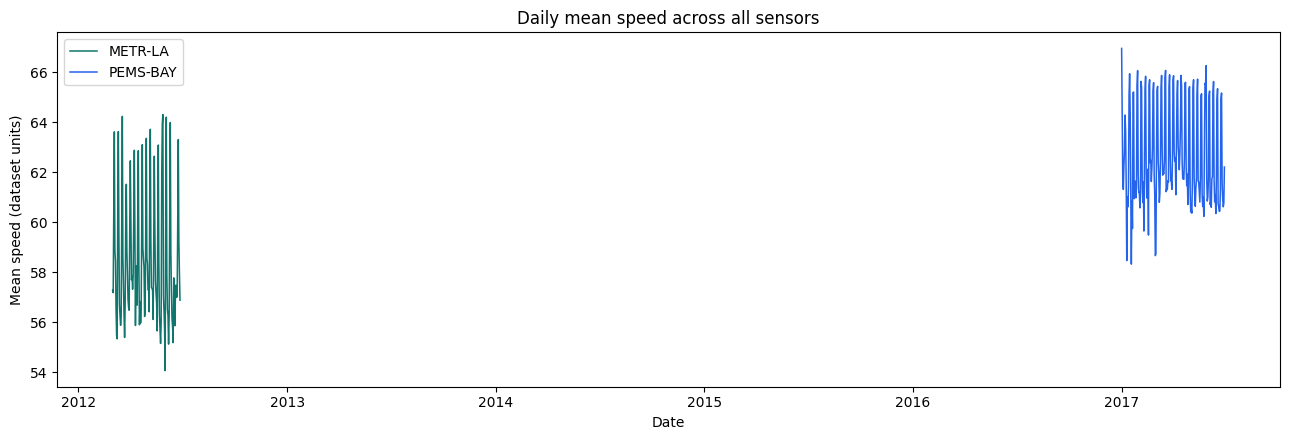

In [4]:
daily_la = la.mean(axis=1).resample('D').mean()
daily_bay = bay.mean(axis=1).resample('D').mean()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(daily_la.index, daily_la, label='METR-LA', color='#0f766e', lw=1.1)
ax.plot(daily_bay.index, daily_bay, label='PEMS-BAY', color='#2563eb', lw=1.1)
ax.set(title='Daily mean speed across all sensors', xlabel='Date', ylabel='Mean speed (dataset units)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / '02_daily_speed_trends.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 5. Average speed by hour of day

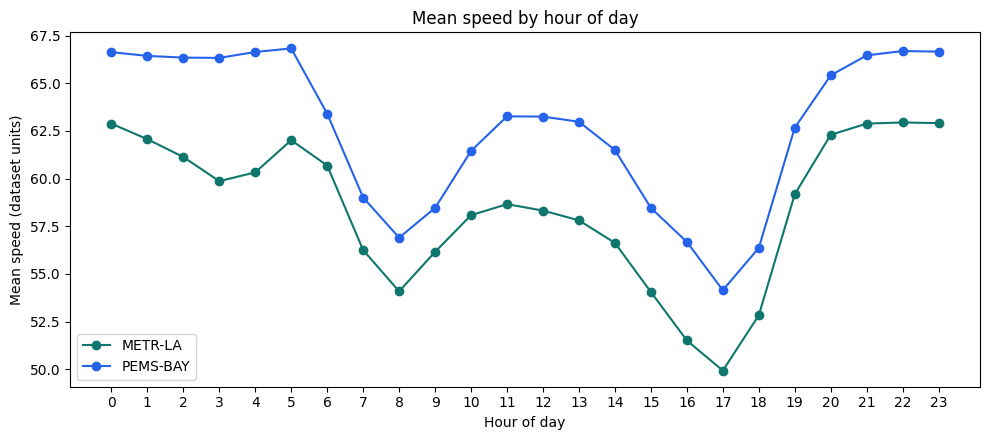

In [5]:
hourly_la = la.groupby(la.index.hour).mean().mean(axis=1)
hourly_bay = bay.groupby(bay.index.hour).mean().mean(axis=1)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hourly_la.index, hourly_la, marker='o', label='METR-LA', color='#0f766e')
ax.plot(hourly_bay.index, hourly_bay, marker='o', label='PEMS-BAY', color='#2563eb')
ax.set(title='Mean speed by hour of day', xlabel='Hour of day', ylabel='Mean speed (dataset units)', xticks=range(24))
ax.legend()
fig.tight_layout()
fig.savefig(FIG / '04_hourly_speed_profiles.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. PEMS-BAY hour-by-weekday speed pattern

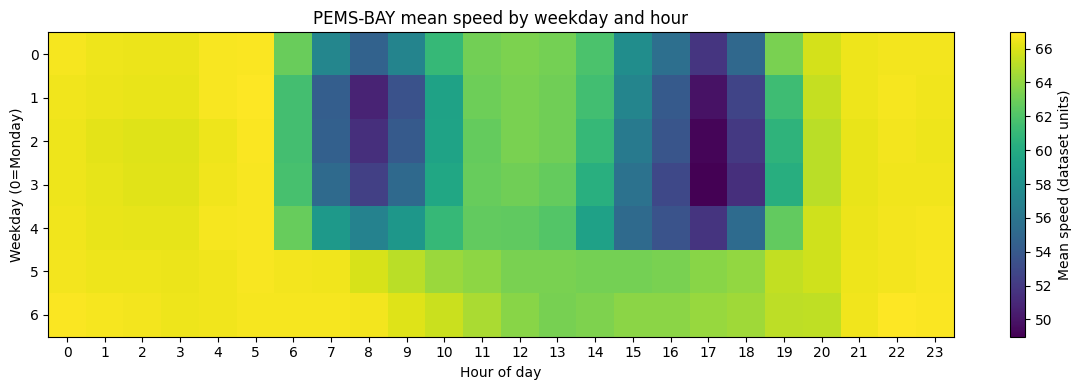

In [6]:
bay_mean = bay.mean(axis=1).rename('mean_speed').to_frame()
bay_mean['weekday'] = bay_mean.index.dayofweek
bay_mean['hour'] = bay_mean.index.hour
weekday_hour = bay_mean.pivot_table(index='weekday', columns='hour', values='mean_speed', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(weekday_hour, aspect='auto', cmap='viridis', interpolation='nearest')
ax.set(title='PEMS-BAY mean speed by weekday and hour', xlabel='Hour of day', ylabel='Weekday (0=Monday)', xticks=range(24))
fig.colorbar(image, ax=ax, label='Mean speed (dataset units)')
fig.tight_layout()
fig.savefig(FIG / '06_weekday_hour_speed_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 7. Speed distributions across both datasets

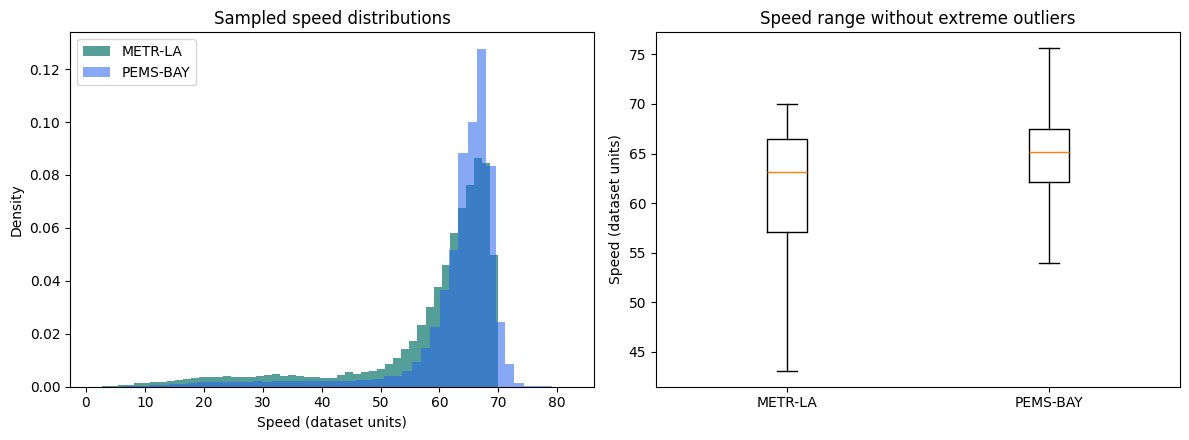

In [7]:
rng = np.random.default_rng(42)
la_values = la.to_numpy().ravel()
bay_values = bay.to_numpy().ravel()
la_values = la_values[np.isfinite(la_values)]
bay_values = bay_values[np.isfinite(bay_values)]
la_values = rng.choice(la_values, min(150_000, len(la_values)), replace=False)
bay_values = rng.choice(bay_values, min(150_000, len(bay_values)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(la_values, bins=50, density=True, alpha=.7, color='#0f766e', label='METR-LA')
axes[0].hist(bay_values, bins=50, density=True, alpha=.55, color='#2563eb', label='PEMS-BAY')
axes[0].set(title='Sampled speed distributions', xlabel='Speed (dataset units)', ylabel='Density')
axes[0].legend()
axes[1].boxplot([la_values, bay_values], showfliers=False)
axes[1].set_xticks([1, 2], ['METR-LA', 'PEMS-BAY'])
axes[1].set(title='Speed range without extreme outliers', ylabel='Speed (dataset units)')
fig.tight_layout()
fig.savefig(FIG / '07_speed_distributions.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 8. Example sensors: speed versus timestamp

Small sample code: change `example_ids` to any four IDs from `bay.columns` to plot different road segments.

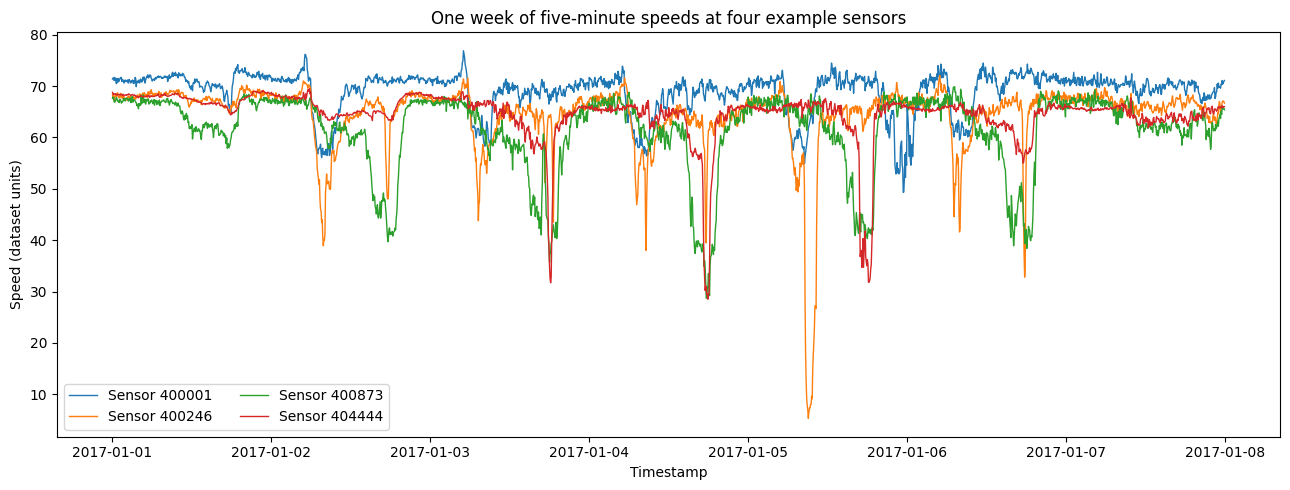

Example sensor IDs: ['400001', '400246', '400873', '404444']


In [8]:
example_ids = bay.columns[[0, 40, 120, 240]].tolist()
example_times = bay.index[:7 * 288]
fig, ax = plt.subplots(figsize=(13, 5))
for sensor_id in example_ids:
    ax.plot(example_times, bay.loc[example_times, sensor_id], lw=1, label=f'Sensor {sensor_id}')
ax.set(title='One week of five-minute speeds at four example sensors', xlabel='Timestamp', ylabel='Speed (dataset units)')
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG / '08_example_sensors_over_time.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Example sensor IDs:', example_ids)

## 9. Sensor-by-time speed heatmap

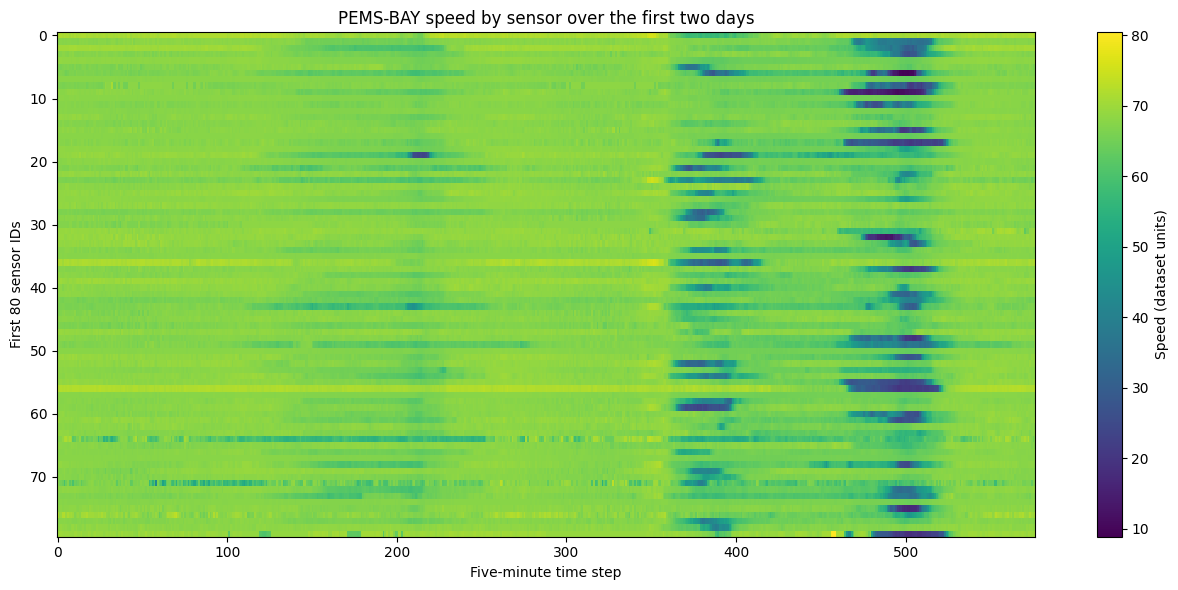

In [9]:
heat_start = bay.index[0]
heat_end = heat_start + pd.Timedelta(days=2)
speed_window = bay.loc[heat_start:heat_end].iloc[:, :80].T
fig, ax = plt.subplots(figsize=(13, 6))
image = ax.imshow(speed_window, aspect='auto', cmap='viridis', interpolation='nearest')
ax.set(title='PEMS-BAY speed by sensor over the first two days', xlabel='Five-minute time step', ylabel='First 80 sensor IDs')
fig.colorbar(image, ax=ax, label='Speed (dataset units)')
fig.tight_layout()
fig.savefig(FIG / '09_sensor_time_speed_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 10. Latitude and longitude: map every PEMS-BAY sensor

Point color shows each sensor's mean observed speed. Coordinates are actual metadata, not generated positions.

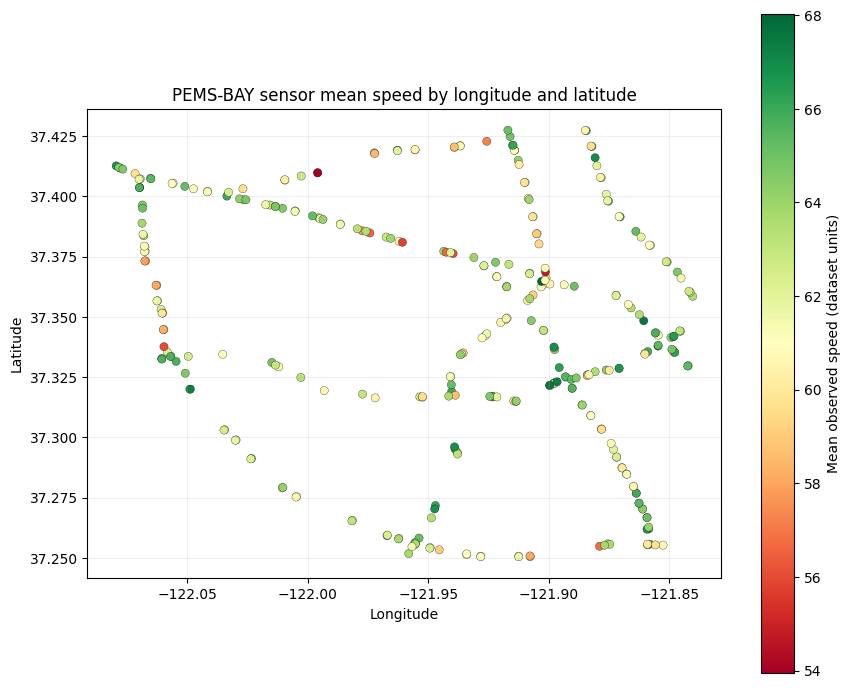

In [10]:
sensor_summary = pd.DataFrame({
    'sensor_id': bay.columns,
    'mean_speed': bay.mean().to_numpy(),
    'median_speed': bay.median().to_numpy(),
    'speed_std': bay.std().to_numpy(),
    'valid_reading_percent': bay.notna().mean().to_numpy() * 100
})
sensor_eda = meta.merge(sensor_summary, on='sensor_id', validate='one_to_one')
sensor_eda.to_csv(METRICS / 'pems_bay_eda_sensor_summary.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(sensor_eda['Longitude'], sensor_eda['Latitude'], c=sensor_eda['mean_speed'], cmap='RdYlGn', s=35, edgecolors='black', linewidths=.2)
fig.colorbar(points, ax=ax, label='Mean observed speed (dataset units)')
ax.set(title='PEMS-BAY sensor mean speed by longitude and latitude', xlabel='Longitude', ylabel='Latitude', aspect='equal')
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG / '10_pems_bay_mean_speed_map.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## 11. Coordinate map colored by freeway and direction

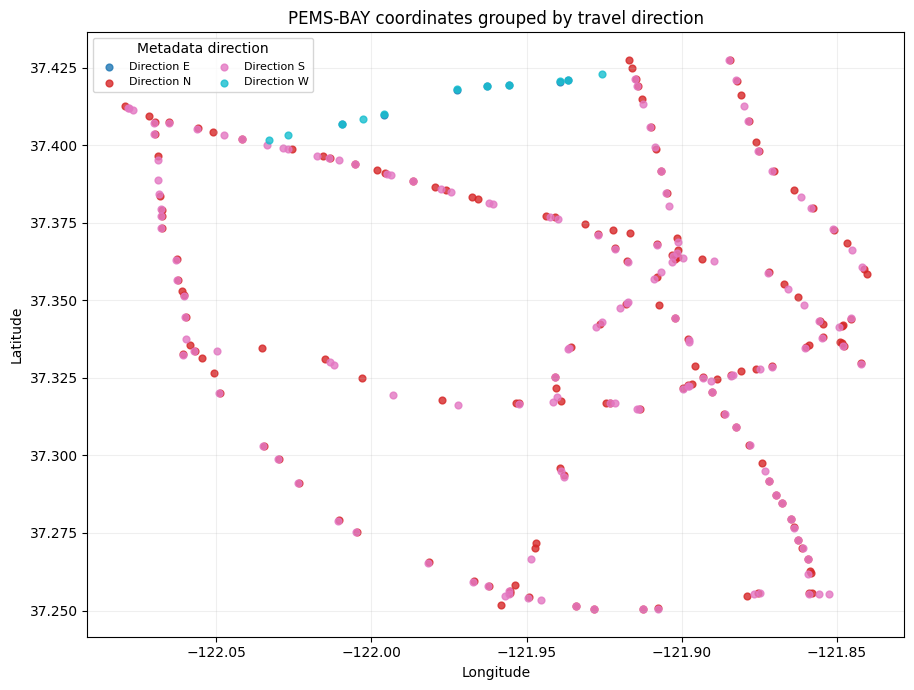

In [11]:
fig, ax = plt.subplots(figsize=(10, 7))
directions = sorted(sensor_eda['Dir'].dropna().astype(str).unique())
colors = plt.cm.tab10(np.linspace(0, 1, max(len(directions), 1)))
for direction, color in zip(directions, colors):
    part = sensor_eda[sensor_eda['Dir'].astype(str) == direction]
    ax.scatter(part['Longitude'], part['Latitude'], s=24, color=color, alpha=.8, label=f'Direction {direction}')
ax.set(title='PEMS-BAY coordinates grouped by travel direction', xlabel='Longitude', ylabel='Latitude', aspect='equal')
ax.legend(title='Metadata direction', ncol=2, fontsize=8)
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG / '11_pems_bay_direction_map.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## 12. Latitude/longitude colored by speed variability

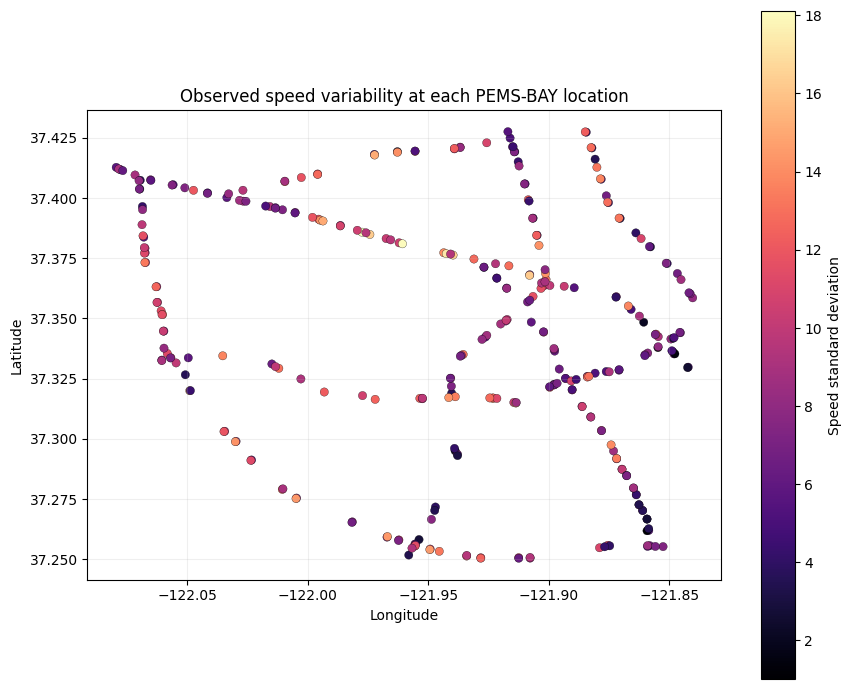

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(sensor_eda['Longitude'], sensor_eda['Latitude'], c=sensor_eda['speed_std'], cmap='magma', s=36, edgecolors='black', linewidths=.2)
fig.colorbar(points, ax=ax, label='Speed standard deviation')
ax.set(title='Observed speed variability at each PEMS-BAY location', xlabel='Longitude', ylabel='Latitude', aspect='equal')
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG / '12_pems_bay_speed_variability_map.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## 13. Sensor speed versus lane count and freeway

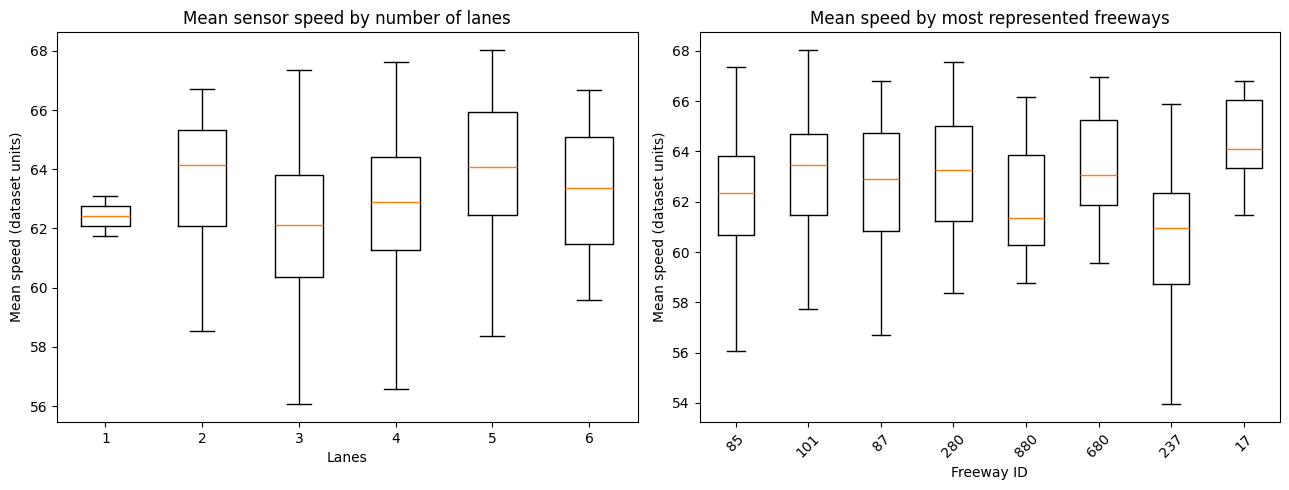

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lanes = sorted(sensor_eda['Lanes'].dropna().unique())
lane_values = [sensor_eda.loc[sensor_eda['Lanes'] == lane, 'mean_speed'].dropna() for lane in lanes]
axes[0].boxplot(lane_values, showfliers=False)
axes[0].set(title='Mean sensor speed by number of lanes', xlabel='Lanes', ylabel='Mean speed (dataset units)', xticks=range(1, len(lanes) + 1), xticklabels=lanes)
top_freeways = sensor_eda['Fwy'].value_counts().head(12).index
freeway_data = [sensor_eda.loc[sensor_eda['Fwy'] == fwy, 'mean_speed'].dropna() for fwy in top_freeways]
axes[1].boxplot(freeway_data, showfliers=False)
axes[1].set(title='Mean speed by most represented freeways', xlabel='Freeway ID', ylabel='Mean speed (dataset units)', xticks=range(1, len(top_freeways) + 1), xticklabels=top_freeways)
axes[1].tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig(FIG / '13_speed_by_road_metadata.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 14. Latitude/longitude colored by lane count

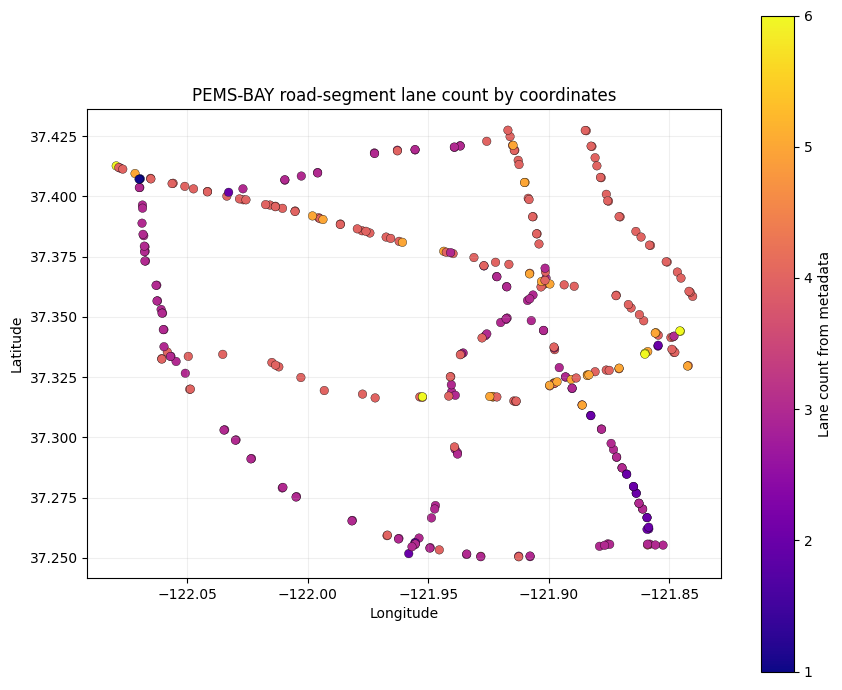

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(sensor_eda['Longitude'], sensor_eda['Latitude'], c=sensor_eda['Lanes'], cmap='plasma', s=38, edgecolors='black', linewidths=.25)
fig.colorbar(points, ax=ax, label='Lane count from metadata')
ax.set(title='PEMS-BAY road-segment lane count by coordinates', xlabel='Longitude', ylabel='Latitude', aspect='equal')
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG / '14_pems_bay_lane_map.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## 15. Sensors with the highest missing-reading rates

,sensor_id,missing_percent,Latitude,Longitude,Fwy,Dir
0,404370,0.008,37.296,-121.939,17,N
1,405613,0.008,37.263,-121.859,87,N
2,404444,0.008,37.265,-121.982,85,S
3,407373,0.008,37.338,-122.060,85,S
4,404461,0.008,37.309,-121.883,87,S
5,408907,0.008,37.322,-121.940,880,N
6,409526,0.008,37.367,-121.922,87,N
7,407364,0.008,37.352,-122.061,85,S
8,405701,0.006,37.317,-121.924,280,N
9,407153,0.006,37.398,-121.875,680,N


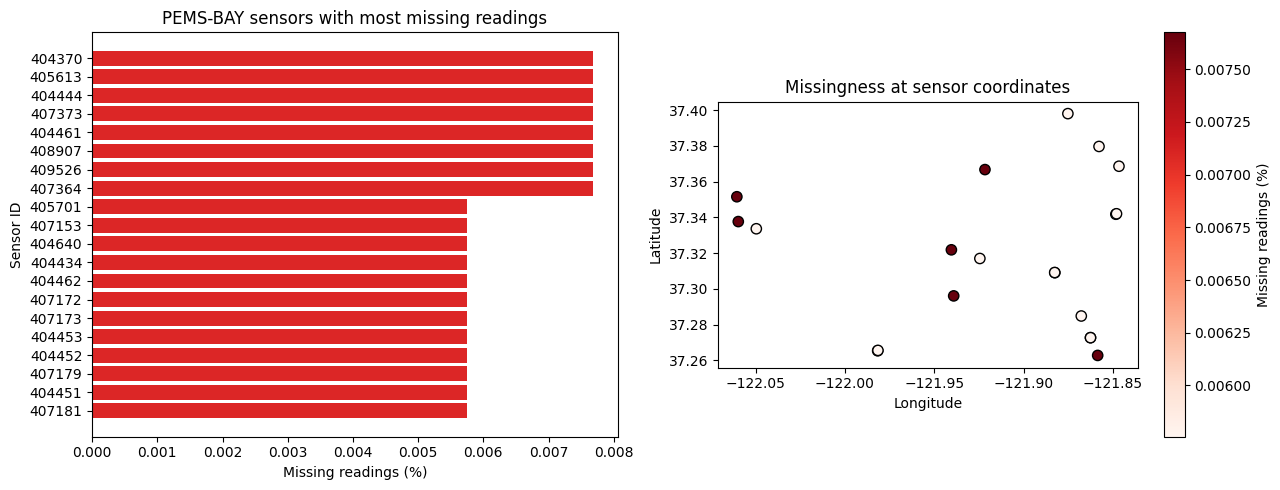

In [15]:
missing = (bay.isna().mean() * 100).rename('missing_percent').reset_index()
missing.columns = ['sensor_id', 'missing_percent']
missing = missing.sort_values('missing_percent', ascending=False).head(20)
missing = missing.merge(meta[['sensor_id', 'Latitude', 'Longitude', 'Fwy', 'Dir']], on='sensor_id', validate='one_to_one')
display(missing.head(10).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(missing['sensor_id'].astype(str), missing['missing_percent'], color='#dc2626')
axes[0].invert_yaxis()
axes[0].set(title='PEMS-BAY sensors with most missing readings', xlabel='Missing readings (%)', ylabel='Sensor ID')
points = axes[1].scatter(missing['Longitude'], missing['Latitude'], c=missing['missing_percent'], cmap='Reds', s=55, edgecolors='black')
fig.colorbar(points, ax=axes[1], label='Missing readings (%)')
axes[1].set(title='Missingness at sensor coordinates', xlabel='Longitude', ylabel='Latitude', aspect='equal')
fig.tight_layout()
fig.savefig(FIG / '15_sensor_missingness_map.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 16. Correlation between example sensor segments

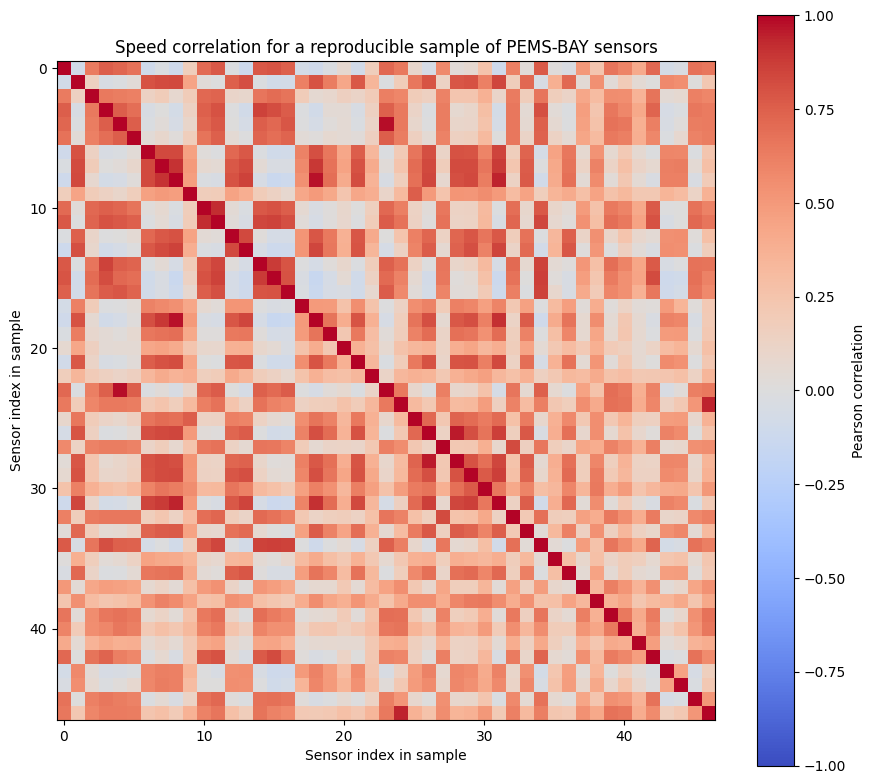

Correlation matrix covers 47 sensor segments.


In [16]:
corr_ids = bay.columns[::7][:48]
correlation = bay[corr_ids].corr(min_periods=100)
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
ax.set(title='Speed correlation for a reproducible sample of PEMS-BAY sensors', xlabel='Sensor index in sample', ylabel='Sensor index in sample')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
fig.savefig(FIG / '16_sensor_speed_correlation.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Correlation matrix covers {len(corr_ids)} sensor segments.')

## 17. Sample code: look up one sensor, plot its speed, and read its coordinates

Change `sensor_id` to any PEMS-BAY traffic column ID. This cell demonstrates the basic data lookup pattern.

Sensor 400001 | freeway 101 | direction N | lanes 5
Latitude 37.364085 | Longitude -121.901149 | name NB 880 rm-n-loop


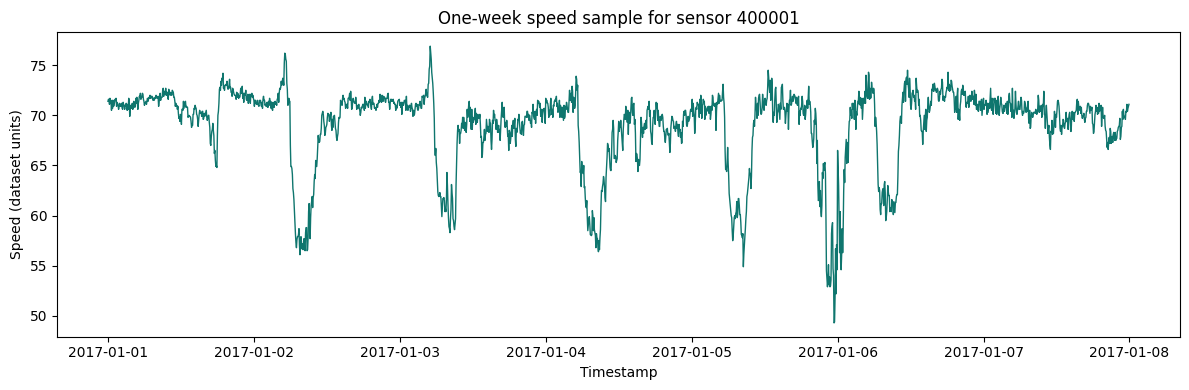

In [17]:
sensor_id = bay.columns[0]
sensor_row = sensor_eda.loc[sensor_eda['sensor_id'] == sensor_id].iloc[0]
one_week = bay[sensor_id].iloc[:7 * 288]
print(f"Sensor {sensor_id} | freeway {sensor_row['Fwy']} | direction {sensor_row['Dir']} | lanes {sensor_row['Lanes']}")
print(f"Latitude {sensor_row['Latitude']:.6f} | Longitude {sensor_row['Longitude']:.6f} | name {sensor_row['Name']}")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(one_week.index, one_week, color='#0f766e', lw=1)
ax.set(title=f"One-week speed sample for sensor {sensor_id}", xlabel='Timestamp', ylabel='Speed (dataset units)')
fig.tight_layout()
fig.savefig(FIG / '17_sample_sensor_speed_over_time.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## EDA summary

The figures above connect five-minute timestamps and observed speeds to actual PEMS-BAY latitude/longitude, highway, direction, and lane fields. METR-LA provides independent time-series speed data but has no matching coordinate metadata in this current folder. Neither speed CSV contains flow or occupancy.